# 04 - Historical results, uncertainty and checkpoint verification

Qidian (Martin) Xing. Independent extension with disclosed Codex assistance. The historical period was previously inspected. Source data and row-level predictions are not redistributed.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root / "src"))
from distress_ml.common import ROOT, PUBLIC, ART
pd.set_option("display.max_columns", 12)
print("Independent extension: saved real-data evidence; no training is triggered.")


Independent extension: saved real-data evidence; no training is triggered.


## Question
How strong is the frozen historical evidence?

## Logic
Read natural prevalence, AP/ROC and annual review budgets together. Separate seen/unseen companies, untuned group stress, seed variation and paired company intervals. This is a previously inspected historical period.

,family,feature_set,AP,ROC_AUC,macro_recall_top5,Brier
0,random_forest,S1,0.217440,0.863641,0.481410,0.025208
2,random_forest,S0,0.218971,0.851734,0.481529,0.024191
4,catboost,S1,0.208033,0.857381,0.473934,0.023732
6,xgboost,S1,0.210893,0.856249,0.492823,0.023218
8,catboost,S0,0.242558,0.841037,0.459817,0.022825
10,xgboost,S0,0.220739,0.840579,0.460577,0.023233
12,xgboost,LAGS,0.257537,0.843732,0.437581,0.022878
14,residual_mlp,S1,0.116323,0.825916,0.323732,0.025200
16,residual_mlp,S0,0.180758,0.842117,0.407689,0.024687
18,mlp,S1,0.189019,0.841056,0.421857,0.023464


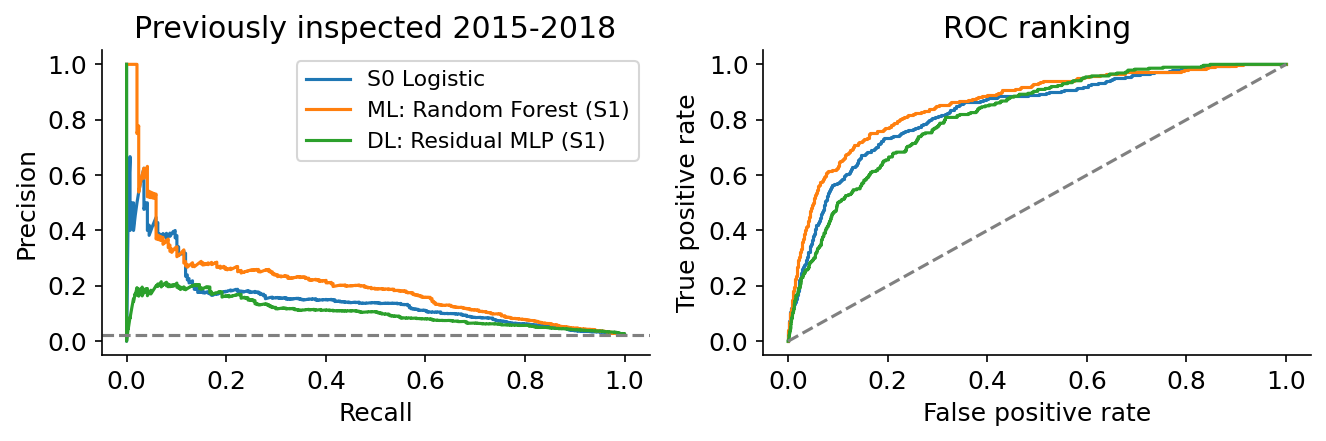

In [2]:
hist = pd.read_csv(PUBLIC / "historical_metrics.csv")
display(hist[hist.score_type == "calibrated"][["family", "feature_set", "AP", "ROC_AUC", "macro_recall_top5", "Brier"]])
display(Image(filename=str(PUBLIC / "figures/ranking_curves.png")))

,model,reference,metric,lower,upper,delta_mean,...,delta_upper,valid_draws,invalid_draws,repetitions,unit,conditional_on_fitted_models
0,final_logistic__S0__c28b1cd7bf_seed42,final_logistic__S0__c28b1cd7bf_seed42,AP,0.104882,0.226134,0.000000,...,0.000000,2000,0,2000,company,True
1,final_logistic__S0__c28b1cd7bf_seed42,final_logistic__S0__c28b1cd7bf_seed42,ROC_AUC,0.792748,0.869183,0.000000,...,0.000000,2000,0,2000,company,True
2,final_logistic__S0__c28b1cd7bf_seed42,final_logistic__S0__c28b1cd7bf_seed42,macro_year_AP,0.113454,0.245474,0.000000,...,0.000000,2000,0,2000,company,True
3,final_logistic__S0__c28b1cd7bf_seed42,final_logistic__S0__c28b1cd7bf_seed42,macro_year_recall_top5,0.245715,0.428485,0.000000,...,0.000000,2000,0,2000,company,True
4,final_random_forest__S1__95d8315d2d_seed42,final_logistic__S0__c28b1cd7bf_seed42,AP,0.146351,0.277053,0.049272,...,0.101701,2000,0,2000,company,True
5,final_random_forest__S1__95d8315d2d_seed42,final_logistic__S0__c28b1cd7bf_seed42,ROC_AUC,0.826723,0.893558,0.029229,...,0.059846,2000,0,2000,company,True
6,final_random_forest__S1__95d8315d2d_seed42,final_logistic__S0__c28b1cd7bf_seed42,macro_year_AP,0.163371,0.291573,0.050679,...,0.104412,2000,0,2000,company,True
7,final_random_forest__S1__95d8315d2d_seed42,final_logistic__S0__c28b1cd7bf_seed42,macro_year_recall_top5,0.381179,0.543553,0.126123,...,0.210581,2000,0,2000,company,True
8,final_residual_mlp__S1__aaac4276aa_seed42,final_logistic__S0__c28b1cd7bf_seed42,AP,0.074249,0.148365,-0.050135,...,0.003400,2000,0,2000,company,True
9,final_residual_mlp__S1__aaac4276aa_seed42,final_logistic__S0__c28b1cd7bf_seed42,ROC_AUC,0.779472,0.847540,-0.017637,...,0.020191,2000,0,2000,company,True


,family,group_fold,companies,positive_companies,AP,ROC_AUC
0,logistic,0,1239,40,0.236162,0.802729
1,xgboost,0,1239,40,0.205067,0.853791
2,residual_mlp,0,1239,40,0.134209,0.810055
3,logistic,1,1197,44,0.136529,0.750448
4,xgboost,1,1197,44,0.152979,0.794280
5,residual_mlp,1,1197,44,0.075056,0.728030
6,logistic,2,1264,35,0.088576,0.832485
7,xgboost,2,1264,35,0.081193,0.812757
8,residual_mlp,2,1264,35,0.062859,0.793366


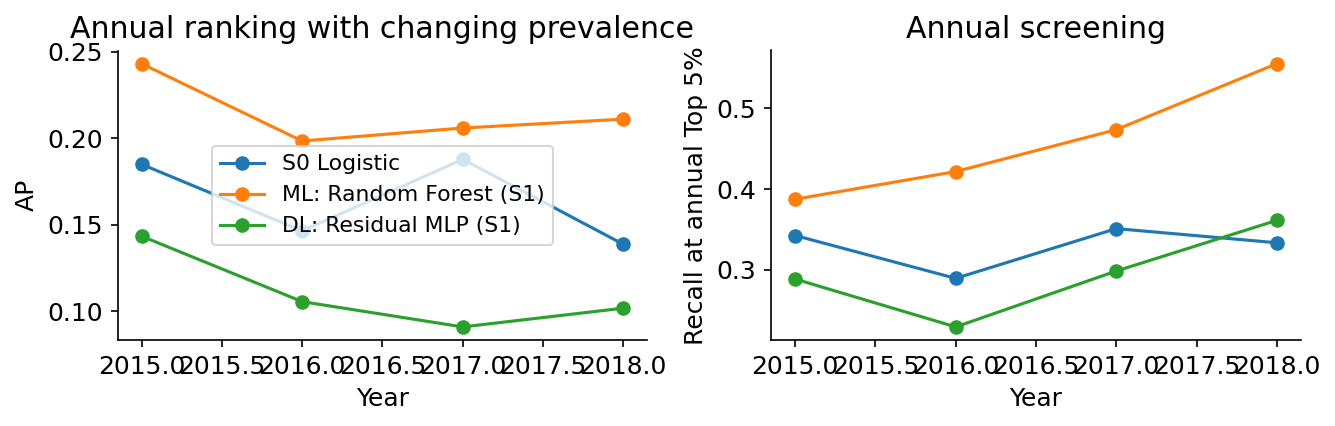

In [3]:
display(pd.read_csv(PUBLIC / "paired_company_bootstrap.csv"))
display(pd.read_csv(PUBLIC / "group_stress_metrics.csv")[["family", "group_fold", "companies", "positive_companies", "AP", "ROC_AUC"]])
display(Image(filename=str(PUBLIC / "figures/annual_performance.png")))

## Same-checkpoint walkthrough
When local artifacts and the authorized snapshot exist, reload the exact DL representative and compare its full historical scores with saved predictions. For a registered error case, reconstruct the financial features, raw logit, calibration and threshold locally. Only consistency flags are displayed; identifiers, source financial rows and full predictions stay local.

In [4]:
from distress_ml.finalize import reproduce
freeze = json.loads((ROOT / "configs/final_freeze.json").read_text())
dl = next(m for m in freeze["models"] if "DL" in m["representative"] and m["seed"] == 42)
if (ROOT / dl["path"]).exists():
    reproduce(dl["label"])
else:
    print("Checkpoint reproduction requires excluded local artifacts and the authorized raw snapshot.")

{"model": "final_residual_mlp__S1__aaac4276aa_seed42", "rows": 12282, "max_score_error": 9.996344030316351e-17, "passed": true}


In [5]:
case_path = ART / "audit/local_failure_cases.json"
if case_path.exists() and (ROOT / dl["path"]).exists():
    from distress_ml.data import load_data
    from distress_ml.features import build_features
    from distress_ml.train import load_pipeline
    from distress_ml.calibration import calibrated_predict
    data = load_data("historical")
    model = load_pipeline(ROOT / dl["path"])
    full_features = build_features(data, model.cfg["feature_set"])
    case = next(x for x in json.loads(case_path.read_text()) if x["representative"] == "DL" and x["cell"] == "FN")
    mask = data.row_id == case["row_id"]
    raw, calibrated = calibrated_predict(model, data.loc[mask], full_features.loc[mask])
    assert np.isclose(raw[0], case["raw_score"], atol=1e-6)
    assert np.isclose(calibrated[0], case["calibrated_score"], atol=1e-6)
    assert (calibrated[0] >= model.threshold) == False
    print("Registered FN walkthrough: feature/logit/calibration/threshold consistency passed.")
else:
    print("Individual cases remain local; public confusion-cell profiles are aggregated.")

Registered FN walkthrough: feature/logit/calibration/threshold consistency passed.


Interpretations are post-hoc predictive descriptions, not causes of failure. See the two reports, model/data cards, contribution disclosure and `results/CLAIMS.csv` before using claims in an interview.